In [46]:
# Import libraries

import numpy as np
import matplotlib.pyplot as plt
import PyDSTool as dst
from PyDSTool.Toolbox import phaseplane as pp

# PyDSTool Practice

Trajectories, phase plane analysis, and bifurcation diagrams of
- saddle node bifurcation $\dot{x}=r-x^2$,
- transcritical bifurcation $\dot{x}=rx-x^2$,
- pitchfork bifurcation $\dot{x}=rx-x^3$,
- two parameter system given by $\dot{x}=r x^2-y$, $\dot{y}=x-y$.

## I. Saddle Node Bifurcation

In [47]:
# Saddle Node Bifurcation (initial state with r=1)

# Create the DSargs instance
DSargs = dst.args(name = "Saddle-Node")

# Parameters
pars = {"r": 1}

# Model equations (ODEs)
varspecs = {"x": "r-x^2"}

# Initial conditions
ics = {"x": 3}

# Domain for x
xdomain = {"x": [-5, 5]}

DSargs.pars = pars
DSargs.varspecs = varspecs
DSargs.ics = ics
DSargs.xdomain = xdomain

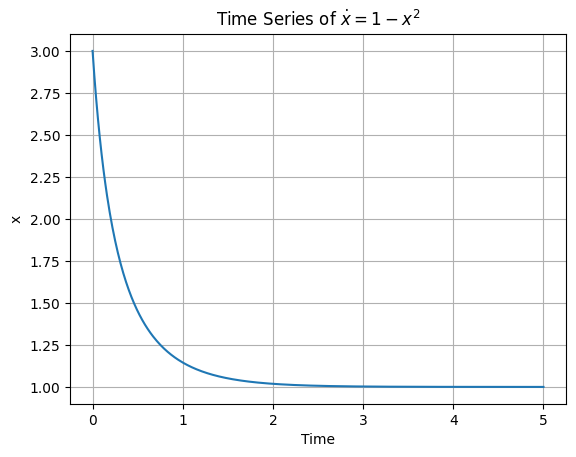

Fixed point 0: [-1.]
Fixed point 1: [1.]


In [48]:
# ODE Solver and time interval
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)
ode_sys.set(tdata = [0, 5])

# Compute a trajectory
trajectory = ode_sys.compute("dimensionless_run")
points = trajectory.sample()

# Time Series Plot
plt.plot(points["t"], points["x"])
plt.grid(True)
plt.title(r"Time Series of $\dot{x}=1-x^2$")
plt.xlabel("Time")
plt.ylabel("x")
plt.show()

# Find fixed points
fp_coord = pp.find_fixedpoints(ode_sys, n = 4, eps = 1e-8)
for i in range(len(fp_coord)):
    print(f"Fixed point {i}: {fp_coord[i]['x']}")

LP Point found 


Text(35.472222222222214, 0.5, 'x')

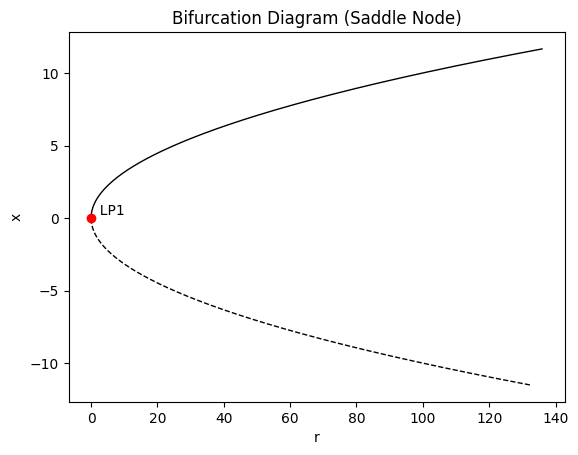

In [49]:
# Bifurcation Analysis, with continuation curve
PC = dst.ContClass(ode_sys)
PCargs = dst.args(name = "SN", type = "EP-C")
PCargs.freepars = ["r"]
PCargs.SaveEigen = True
PCargs.LocBifPoints = ["LP"]
PCargs.MaxNumPoints = 200
PCargs.StepSize = 0.01
PCargs.MaxStepSize = 0.75
PCargs.MinStepSize = 1e-5
PC.newCurve(PCargs)

PC["SN"].forward()
PC["SN"].backward()
PC["SN"].display(("r", "x"), stability = True)

plt.title("Bifurcation Diagram (Saddle Node)")

# Remove all point labels of type P
PC.plot.toggleAll("off", bytype = "P")
plt.xlabel("r")
plt.ylabel("x")

## II. Transcritical Bifurcation

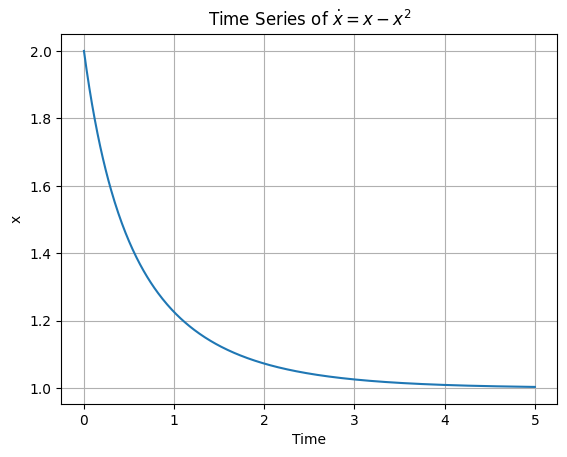

Fixed point 0: [0.]
Fixed point 1: [1.]
BP Point found 


Text(26.722222222222214, 0.5, 'x')

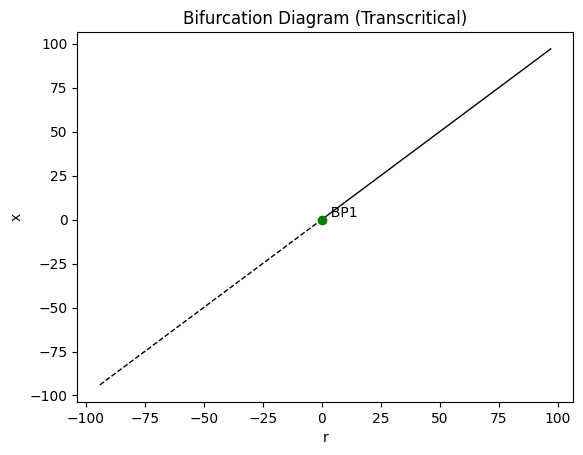

In [50]:
# Transcritical Bifurcation (with initial r = 1)
DSargs = dst.args(name = "Transcritical")

pars = {"r": 1}
varspecs = {"x": "r * x - x^2"}
ics = {"x": 2}
xdomain = {"x": [-5, 5]}

DSargs.pars = pars
DSargs.varspecs = varspecs
DSargs.ics = ics
DSargs.xdomain = xdomain

# ODE Solver
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)
ode_sys.set(tdata = [0, 5])
traj = ode_sys.compute("dimensionless_run")
points = traj.sample()

plt.plot(points["t"], points["x"])
plt.grid(True)
plt.title(r"Time Series of $\dot{x}=x-x^2$")
plt.xlabel("Time")
plt.ylabel("x")
plt.show()

# Fixed points
fp_coord = pp.find_fixedpoints(ode_sys, n = 4, eps = 1e-8)
for i in range(len(fp_coord)):
    print(f"Fixed point {i}: {fp_coord[i]['x']}")

# Bifurcation Analysis
PC = dst.ContClass(ode_sys)
PCargs = dst.args(name = "TC", type = "EP-C")
PCargs.freepars = ["r"]
PCargs.SaveEigen = True
PCargs.LocBifPoints = ["BP"]
PCargs.MaxNumPoints = 200
PCargs.StepSize = 0.01
PCargs.MaxStepSize = 0.75
PCargs.MinStepSize = 1e-5
PC.newCurve(PCargs)

PC["TC"].forward()
PC["TC"].backward()
PC["TC"].display(("r", "x"), stability = True)

# Remove all point labels of type P
PC.plot.toggleAll("off", bytype = "P")
plt.title("Bifurcation Diagram (Transcritical)")
plt.xlabel("r")
plt.ylabel("x")

## III. Pitchfork Bifurcation

(Specifically a supercritical pitchfork)

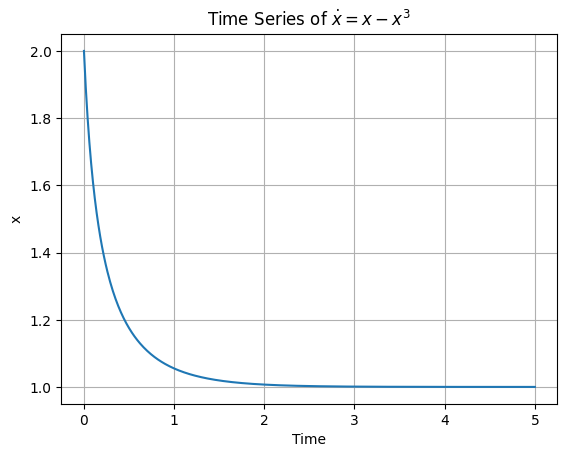

Fixed point 0: [-1.]
Fixed point 1: [1.]
BP Point found 
BP Point found 


Text(44.347222222222214, 0.5, 'x')

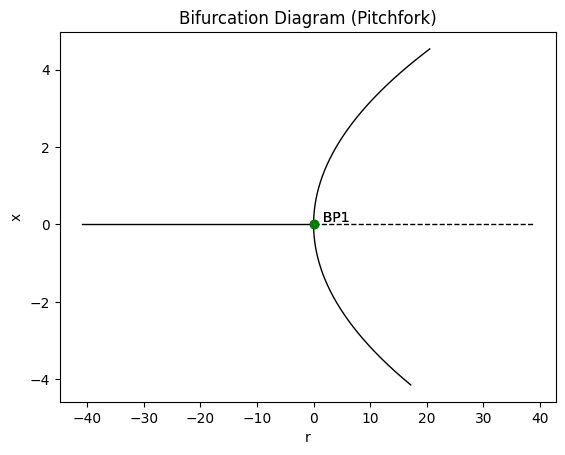

In [51]:
# Pitchfork Bifurcation (with initial r = 1)
DSargs = dst.args(name = "Transcritical")

pars = {"r": 1}
varspecs = {"x": "r * x - x^3"}
ics = {"x": 2}
xdomain = {"x": [-5, 5]}

DSargs.pars = pars
DSargs.varspecs = varspecs
DSargs.ics = ics
DSargs.xdomain = xdomain

# ODE Solver
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)
ode_sys.set(tdata = [0, 5])
traj = ode_sys.compute("dimensionless_run")
points = traj.sample()

plt.plot(points["t"], points["x"])
plt.grid(True)
plt.title(r"Time Series of $\dot{x}=x-x^3$")
plt.xlabel("Time")
plt.ylabel("x")
plt.show()

# Fixed points
fp_coord = pp.find_fixedpoints(ode_sys, n = 4, eps = 1e-8)
for i in range(len(fp_coord)):
    print(f"Fixed point {i}: {fp_coord[i]['x']}")

# Bifurcation Analysis
# First branch
PC = dst.ContClass(ode_sys)
PCargs = dst.args(name = "PF", type = "EP-C")
PCargs.freepars = ["r"]
PCargs.SaveEigen = True
PCargs.LocBifPoints = ["BP"]
PCargs.MaxNumPoints = 400
PCargs.StepSize = 0.01
PCargs.MaxStepSize = 0.05
PCargs.MinStepSize = 1e-5
PC.newCurve(PCargs)
PC["PF"].forward()
PC["PF"].backward()

# Second branch
ode_sys.set(pars={"r": -1})
ode_sys.set(ics={"x": 0})
PCargs2 = dst.args(name="PF2", type="EP-C")
PCargs2.initpoint = {"x": 0, "r": -1}
PCargs2.freepars = ["r"]
PCargs2.SaveEigen = True
PCargs2.LocBifPoints = ["BP"]
PCargs2.MaxNumPoints = 400
PCargs2.StepSize = 0.1
PCargs.MaxStepSize = 0.05
PCargs2.MinStepSize = 1e-5
PC.newCurve(PCargs2)
PC["PF2"].forward()
PC["PF2"].backward()

# Display both
PC.display(("r", "x"), stability = True)

# Remove all point labels of type P
PC.plot.toggleAll("off", bytype = "P")

plt.title("Bifurcation Diagram (Pitchfork)")
plt.xlabel("r")
plt.ylabel("x")

## IV. Two Dimensional Model

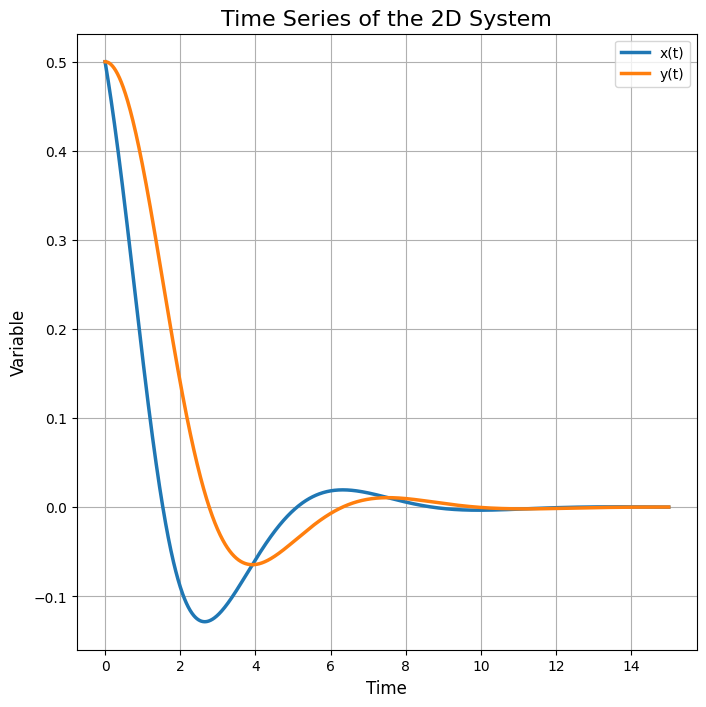

Fixed point 0: (0.0, 0.0)
Fixed point 1: (1.0, 1.0)


In [52]:
# DSargs instance
DSargs = dst.args(name = "Two-Dimensional")
pars = {"r": 1}
varspecs = {"x": "r * x^2 - y",
           "y": "x - y"}
ics = {"x": 0.5, "y": 0.5}
xdomain = {"x": [0, 5], "y": [0, 5]}
pdomain = {"r": [0.1, 20]} # Set the range of r later on in bifurcation diagram

DSargs.pars = pars
DSargs.varspecs = varspecs
DSargs.ics = ics
DSargs.xdomain = xdomain
DSargs.pdomain = pdomain

# ODE Solver
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)
ode_sys.set(tdata=[0, 15])
trajectory = ode_sys.compute('dimensionless_run')
points = trajectory.sample()

# Time Series
fig_A1, ax_A1 = plt.subplots(figsize=(8, 8))
ax_A1.plot(points['t'], points['x'], label='x(t)', lw=2.5)
ax_A1.plot(points['t'], points['y'], label='y(t)', lw=2.5)
ax_A1.set_title('Time Series of the 2D System', fontsize=16)
ax_A1.set_xlabel('Time', fontsize=12)
ax_A1.set_ylabel('Variable', fontsize=12)
plt.legend()
ax_A1.grid(True)
plt.show()

# Fixed points
fp_coord = pp.find_fixedpoints(ode_sys, n = 4, eps = 1e-8)
for i in range(len(fp_coord)):
    print(f"Fixed point {i}: ({fp_coord[i]['x']}, {fp_coord[i]['y']})")


B Point found 
B Point found 
B Point found 
B Point found 


Text(55.847222222222214, 0.5, 'x')

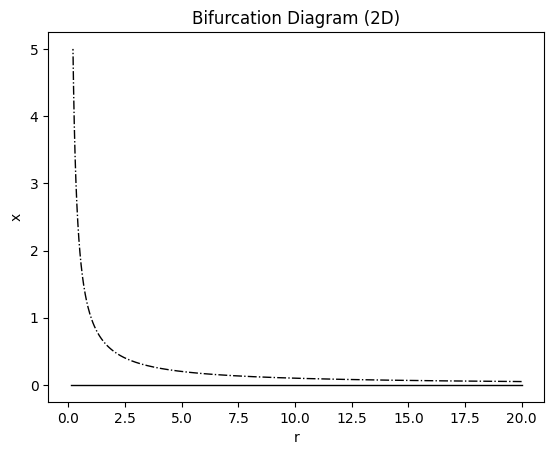

In [53]:
# Bifurcation Diagram
# Unstable Branch
PC = dst.ContClass(ode_sys)
PCargs = dst.args(name = "U", type = "EP-C")
PCargs.freepars = ["r"]
PCargs.SaveEigen = True
PCargs.LocBifPoints = ["B"]
PCargs.StopAtPoints = ["B"] # Use this to fix range of r
PCargs.MaxNumPoints = 400
PCargs.StepSize = 0.01
PCargs.MaxStepSize = 0.05
PCargs.MinStepSize = 1e-5
PC.newCurve(PCargs)
PC["U"].forward()
PC["U"].backward()

# Stable Branch
PCargs2 = dst.args(name = "S", type = "EP-C")
PCargs2.initpoint = {"x": 0, "y": 0, "r": 1}
PCargs2.freepars = ["r"]
PCargs2.SaveEigen = True
PCargs2.LocBifPoints = ["B"]
PCargs2.StopAtPoints = ["B"] # Use this to fix range of r
PCargs2.MaxNumPoints = 400
PCargs2.StepSize = 0.01
PCargs2.MaxStepSize = 0.05
PCargs2.MinStepSize = 1e-5
PC.newCurve(PCargs2)
PC["S"].forward()
PC["S"].backward()

# Display
PC.display(("r", "x"), stability = True)

# To remove those points labels and shapes
# Can set bytype = "B" for example to only remove "B" types
PC.plot.toggleLabels("off")
PC.plot.togglePoints("off")

plt.title("Bifurcation Diagram (2D)")
plt.xlabel("r")
plt.ylabel("x")